In [1]:
import osgeo
import rasterio
import rioxarray
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
#import tifffile

Open data and read it as array

In [2]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

In [3]:
path_LC_Hansen2 = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000.tif'

In [4]:
path_GLC_E0N10 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E0N10_Annual.tif'

In [5]:
path_GLC_E0N15 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E0N15_Annual.tif'

In [6]:
path_GLC_E25N70 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E20-E25/GLC_FCS30D_20002022_E25N70_Annual.tif'

In [7]:
path_GLC_W55S5 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_W55-W60/GLC_FCS30D_20002022_W55S5_Annual.tif'

In [8]:
LCHansen2000 = rasterio.open(path_LC_Hansen)

In [9]:
LCHansen20002 = rasterio.open(path_LC_Hansen2)

Read GLC data as xarray

In [10]:
GLC_FCS302000E0N10 = rioxarray.open_rasterio(path_GLC_E0N10)

In [11]:
GLC_FCS302000E0N15 = rioxarray.open_rasterio(path_GLC_E0N15)

In [12]:
GLC_FCS302000E25N70 = rioxarray.open_rasterio(path_GLC_E25N70)

In [13]:
GLC_FCS302000W55S5 = rioxarray.open_rasterio(path_GLC_W55S5)

Show metadata

with tifffile.TiffFile(path_LC_Hansen2) as tif:
    for page in tif.pages:
        print(page.tags)

with tifffile.TiffFile(path_LC_Hansen2) as tif:
    for page in tif.pages:
        for tag in page.tags.values():
            print(tag.name, tag.value)

with tifffile.TiffFile(path_LC_Hansen2) as tif:
    print(tif.pages[0].tags)

Select zear 2000

In [14]:
GLC_FCS302000E25N70

<xarray.DataArray (band: 23, y: 18554, x: 18554)> Size: 8GB
[7917771068 values with dtype=uint8]
Coordinates:
  * band         (band) int64 184B 1 2 3 4 5 6 7 8 9 ... 16 17 18 19 20 21 22 23
  * y            (y) float64 148kB 70.0 70.0 70.0 70.0 ... 65.0 65.0 65.0 65.0
  * x            (x) float64 148kB 25.0 25.0 25.0 25.0 ... 30.0 30.0 30.0 30.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [14]:
GLC_FCS302000E0N10band1 = GLC_FCS302000E0N10.sel(band=1)

In [15]:
GLC_FCS302000E0N15band1 = GLC_FCS302000E0N15.sel(band=1)

In [16]:
GLC_FCS302000E25N70band1 = GLC_FCS302000E25N70.sel(band=1)

In [17]:
GLC_FCS302000W55S5band1 = GLC_FCS302000W55S5.sel(band=1)

In [18]:
GLC_FCS302000E0N10band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
[344250916 values with dtype=uint8]
Coordinates:
  * y            (y) float64 148kB 10.0 10.0 9.999 9.999 ... 5.001 5.0 5.0 5.0
  * x            (x) float64 148kB 0.0001347 0.0004042 0.0006737 ... 5.0 5.0 5.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Show bounds

left → min X (longitude or easting)
right → max X
bottom → min Y (latitude or northing)
top → max Y

In [22]:
bounds = LCHansen2000.bounds
print(bounds)

BoundingBox(left=-180.0, bottom=-90.0, right=180.0, top=90.0)


In [23]:
bounds = GLC_FCS302000E0N10band1.rio.bounds()
print(bounds)

(0.0, 4.99979746553392, 5.00020253446608, 10.0)


In [24]:
bounds = GLC_FCS302000E0N15band1.rio.bounds()
print(bounds)

(0.0, 9.99979746553392, 5.00020253446608, 15.0)


In [25]:
bounds = GLC_FCS302000E25N70band1.rio.bounds()
print(bounds)

(25.0, 64.99979746553392, 30.000202534466077, 70.0)


In [26]:
bounds = GLC_FCS302000W55S5band1.rio.bounds()
print(bounds)

(-55.0, -10.00020253446608, -49.999797465533916, -5.0)


## LH forest classification

Tree cover, broadleaved, evergreen, closed to open (>15%) 50
Tree cover, broadleaved, deciduous, closed to open (>15%) 60
Tree cover, broadleaved, deciduous, closed (>40%) 61
Tree cover, broadleaved, deciduous, open (15 – 40%) 62
Tree cover, needle leaved, evergreen, closed to open (>15%) 70
Tree cover, needle leaved, evergreen, closed (>40%) 71
Tree cover, needle leaved, evergreen, open (15 – 40%) 72
Tree cover needle leaved deciduous, closed to open (>15%) 80
Tree cover needle leaved deciduous, closed (>40%) 81
Tree cover needle leaved deciduous, open (15 – 40%) 82
Tree cover, mixed leaf type (broadleaved and needle leaved) 90

## GLC forest classification

  'Open_evergreen_broadleaved_forest', 51
  'Closed_evergreen_broadleaved_forest', 52
  'Open_deciduous_broadleaved_forest', 61
  'Closed_deciduous_broadleaved_forest', 62
  'Open_evergreen_needle_leaved_forest', 71
  'Closed_evergreen_needle_leaved_forest', 72
  'Open_deciduous_needle_leaved_forest', 81
  'Closed_deciduous_needle_leaved_forest',  82
  'Open_mixed_leaf_forest', 91
  'Closed_mixed_leaf_forest', 92

In [ ]:
LCHansen2000array = LCHansen2000.read(1)
LCHansen2000array.shape
print(LCHansen2000array[:-50, :-50])

In [ ]:
type(LCHansen2000array)

Check coordinate system

In [28]:
LCHansen2000.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [29]:
GLC_FCS302000E0N10band1.rio.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

Select areas with forest

In [93]:
mask = (LCHansen2000array >= 50) & (LCHansen2000array <= 90)
# Apply mask (set others to NaN for visualization)
LCHansen2000filtered = np.where(mask, LCHansen2000array, np.nan)

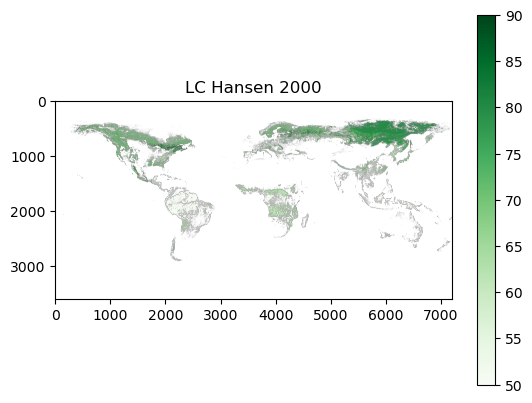

In [94]:
pyplot.imshow(LCHansen2000filtered, cmap='Greens')
pyplot.title("LC Hansen 2000")
pyplot.colorbar()

In [ ]:
GLC_FCS302000E0N10band1.to_dataarray()

In [ ]:
mask = (GLC_FCS302000E0N10band1 >= 51) & (GLC_FCS302000E0N10band1 <= 92)
# Apply mask (set others to NaN for visualization)
GLC_FCS302000E0N10band1filtered = np.where(mask, GLC_FCS302000E0N10band1, np.nan)

In [ ]:
GLC_FCS302000E0N10band1filtered.plot()

In [ ]:
pyplot.imshow(GLC_FCS302000E0N10band1filtered, cmap='Greens')
pyplot.colorbar()
pyplot.show()

In [ ]:
mask = (GLC_FCS302000E0N10band1 >= 51) & (GLC_FCS302000E0N10band1 <= 92)
# Apply mask (set others to NaN for visualization)
GLC_FCS302000E0N10band1filtered = np.where(mask, GLC_FCS302000E0N10band1, np.nan)

In [ ]:
pyplot.imshow(array3, cmap='Greens')
pyplot.title("GLC_FCS30 2000 E0N15")
pyplot.colorbar()

In [ ]:
mask = (GLC_FCS302000E0N10band1 >= 51) & (GLC_FCS302000E0N10band1 <= 92)
# Apply mask (set others to NaN for visualization)
GLC_FCS302000E0N10band1filtered = np.where(mask, GLC_FCS302000E0N10band1, np.nan)

In [ ]:
pyplot.imshow(array3, cmap='Greens')
pyplot.title("GLC_FCS30 2000 E0N15")
pyplot.colorbar()

In [ ]:
mask = (GLC_FCS302000E0N10band1 >= 51) & (GLC_FCS302000E0N10band1 <= 92)
# Apply mask (set others to NaN for visualization)
GLC_FCS302000E0N10band1filtered = np.where(mask, GLC_FCS302000E0N10band1, np.nan)

In [ ]:
pyplot.imshow(array3, cmap='Greens')
pyplot.title("GLC_FCS30 2000 E0N15")
pyplot.colorbar()

Define bounding box for LC Hansen

In [18]:
minx, miny, maxx, maxy = 0.0, 4.999797465533919, 5.000202534466081, 10.0

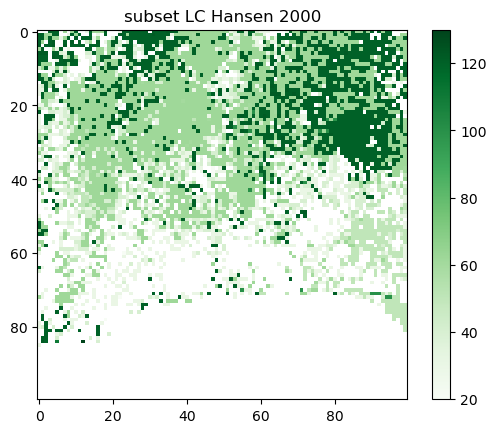

In [19]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

mask = (subset >= 20) & (subset <= 150) 
# Apply mask (set others to NaN for visualization)
filtered3 = np.where(mask, subset, np.nan)

pyplot.imshow(filtered3, cmap='Greens')
pyplot.title("subset LC Hansen 2000")
pyplot.colorbar()